<a href="https://colab.research.google.com/github/liscouetmael/tableau_public/blob/main/Projet_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
from torchvision import datasets, transforms
from torch import nn
from torch.utils.data import DataLoader

Une fois que j'ai fait mes imports (datasets et une bibliothèques de bibliothèques de données et transfroms permet la normalisation et la transformation des données en vecteurs), je crée mes tenseurs de données d'entraînement et de données de test

In [ ]:
train_data = datasets.MNIST(root = 'data', train = True, download = True, transform = transforms.ToTensor())

test_data = datasets.MNIST(root = 'data', train =False, download = True, transform = transforms.ToTensor())

100%|██████████| 9.91M/9.91M [00:00<00:00, 24.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 611kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.51MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.64MB/s]


Une fois que j'ai créé mes données, je les envoie dans le DataLoader pour qu'il charge les données avant entraînement

### Qu'est-ce que fait le `DataLoader` ?

Le `DataLoader` prend votre jeu de données (comme `train_data` ou `test_data`) et l'emballe dans un **itérateur**. Il automatise plusieurs tâches complexes :

1. **Le découpage en lots (Batching)** :
   Au lieu d'envoyer les 60 000 images de MNIST en une seule fois (ce qui sature la mémoire) ou une par une (ce qui est très lent), le `DataLoader` regroupe les données en petits paquets appelés **batches** (par exemple, 64 images à la fois).

2. **Le mélange des données (Shuffling)** :
   Pour l'entraînement, il mélange aléatoirement les images à chaque nouvelle époque (`shuffle=True`). Cela évite que le modèle n'apprenne l'ordre des exemples plutôt que leurs caractéristiques.

3. **Le chargement multitâche (Multiprocessing)** :
   Il peut charger les données en arrière-plan à l'aide de plusieurs processus CPU (`num_workers`), afin que le processeur graphique (GPU) n'ait jamais à attendre les données.

In [ ]:
train_dataloader = DataLoader(train_data, batch_size = 64, shuffle = True)

test_dataloader = DataLoader(test_data, batch_size = 64, shuffle = True)

### Création du Réseau de Neurones

Pour créer un réseau de neurones avec PyTorch :
1. On hérite de la classe `nn.Module`.
2. On définit les couches dans la méthode de construction `__init__`.
3. On définit le passage des données dans la méthode `forward`.

Comme les images MNIST font $28 \times 28$ pixels ($784$ pixels au total) et qu'il y a 10 classes possibles (les chiffres de 0 à 9), notre réseau aura :
- Une couche d'entrée de taille $784$.
- Une ou plusieurs couches cachées.
- Une couche de sortie de taille $10$.

In [ ]:
class ReseauBasique(nn.Module):
  def __init__(self):
    super().__init__() #récupère le init de nn.Module
    self.flatten = nn.Flatten()# nn.Flatten permet de transformer une image 2D (28x28) en un vecteur 1D (784)

    self.linear_relu = nn.Sequential(
        nn.Linear(784,128),
        nn.ReLU(),
        nn.Linear(128,32),
        nn.ReLU(),
        nn.Linear(32,10)
    ) #je fais autant de couches que je veux,
    #en linéaire la couche n-1 sort autant de noeuds que la couche n en entrée

  def forward(self, x):
      x = self.flatten(x)
      return self.linear_relu(x) #lorsque je fais passer mon vecteur d'image dans le réseau, je le normalise et je lui applique la séquence


model = ReseauBasique()
print(model)

ReseauBasique(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=10, bias=True)
  )
)


Pour entraîner le modèle, on doit définir deux éléments clés :

La fonction de perte (Loss Function) : Elle mesure l'écart entre les prédictions du modèle et les vraies étiquettes. Pour un problème de classification multi-classe comme MNIST, on utilise généralement la perte d'entropie croisée (nn.CrossEntropyLoss).
L'optimiseur (Optimizer) : C'est l'algorithme qui ajuste les poids du réseau pour réduire la perte (par exemple, la descente de gradient stochastique SGD ou Adam).

### Définition de la fonction de perte et de l'optimiseur

- **Fonction de perte (`Loss Function`)** : Nous utilisons `nn.CrossEntropyLoss()`. Elle combine un `LogSoftmax` et la perte de négative log-vraisemblance (`NLLLoss`) en une seule classe, idéale pour la classification.
- **Optimiseur (`Optimizer`)** : Nous utilisons `torch.optim.SGD` (Stochastic Gradient Descent) pour mettre à jour les paramètres du modèle, en lui passant les paramètres à optimiser (`model.parameters()`) et un taux d'apprentissage (`lr` ou *Learning Rate*).

### Concepts Clés : Cross-Entropy & Poids du Réseau

#### 1. C'est quoi les poids d'un réseau ?
Les **poids (weights)** et les **biais (biases)** sont les paramètres ajustables de votre réseau.
- Chaque connexion entre deux neurones possède un poids. Quand une information passe, elle est multipliée par ce poids.
- Au début, ils sont initialisés de manière aléatoire.
- **L'entraînement consiste à ajuster ces poids** petit à petit pour que le réseau donne la bonne réponse.

#### 2. C'est quoi la Cross-Entropy (Entropie Croisée) ?
C'est une mesure de l'écart entre deux distributions de probabilité.
- Votre modèle sort 10 valeurs (logits) pour une image (une pour chaque chiffre de 0 à 9). On transforme ces valeurs en probabilités (avec Softmax) pour obtenir, par exemple : `[0.1, 0.05, 0.7, ..., 0.01]` (le modèle pense à 70% que c'est un 2).
- La réalité (la vraie étiquette) est représentée sous forme de probabilité parfaite (One-hot encoding) : `[0, 0, 1, ..., 0]` (c'est sûr à 100% que c'est un 2).
- **La Cross-Entropy calcule l'écart entre ces deux distributions**. Plus la probabilité attribuée à la bonne classe est proche de 1, plus la Cross-Entropy est proche de 0. Si le modèle se trompe lourdement, la perte devient immense.

### Option 1 : Utilisation standard avec les bibliothèques PyTorch (Rappel)

Voici le code classique utilisant l'API haut niveau de PyTorch.

### 1. Formalisation Mathématique de la Cross-Entropy (Entropie Croisée)

Soit un problème de classification à $C$ classes (pour MNIST, $C = 10$). Pour un exemple donné :
- $y \in \mathbb{R}^C$ est le vecteur cible sous forme d'encodage *one-hot*. Si la vraie classe est $c^*$, alors $y_{c^*} = 1$ et $y_c = 0$ pour tout $c \neq c^*$.
- $z \in \mathbb{R}^C$ est le vecteur des scores bruts (les *logits*) sortis par la dernière couche du réseau.

#### Étape A : La fonction Softmax
Pour transformer les scores bruts $z$ en une distribution de probabilités $\hat{y} \in \mathbb{R}^C$, on applique la fonction Softmax :

$$\hat{y}_i = \sigma(z)_i = \frac{e^{z_i}}{\sum_{j=1}^{C} e^{z_j}} \quad \text{pour } i = 1, \dots, C$$

#### Étape B : L'Entropie Croisée
La perte d'entropie croisée $\mathcal{L}$ pour un unique exemple est définie par :

$$\mathcal{L}(y, \hat{y}) = - \sum_{i=1}^{C} y_i \log(\hat{y}_i)$$

Comme $y$ est un vecteur *one-hot* où seule la composante de la vraie classe $c^*$ vaut $1$, la formule se simplifie à :

$$\mathcal{L}(y, \hat{y}) = - \log(\hat{y}_{c^*}) = - \log\left( \frac{e^{z_{c^*}}}{\sum_{j=1}^{C} e^{z_j}} \right)$$

Pour un lot (batch) de taille $N$, la fonction de perte globale $J$ est la moyenne des pertes individuelles :

$$J = \frac{1}{N} \sum_{n=1}^{N} \mathcal{L}(y^{(n)}, \hat{y}^{(n)})$$

### 2. Écriture Matricielle d'une Couche et de la Descente de Gradient

#### Formulation Matricielle d'une Couche Linéaire
Soit une couche d'un réseau de neurones prenant en entrée une matrice d'activation $X \in \mathbb{R}^{N \times d_{in}}$ (où $N$ est la taille du batch et $d_{in}$ la dimension d'entrée, soit 784 pour MNIST).
La transformation linéaire associée à cette couche est définie par :

$$Z = X W + b$$

Où :
- $W \in \mathbb{R}^{d_{in} \times d_{out}}$ est la matrice des poids.
- $b \in \mathbb{R}^{1 \times d_{out}}$ est le vecteur de biais, projeté par diffusion (broadcasting) sur chaque ligne du batch.
- $Z \in \mathbb{R}^{N \times d_{out}}$ est la matrice des logits de sortie.

#### Algorithme de la Descente de Gradient Stochastique (SGD)
Le but est de minimiser la fonction de coût globale $J$ en ajustant les paramètres $W$ et $b$. À chaque étape d'optimisation (step), la mise à jour s'écrit :

$$W^{(t+1)} = W^{(t)} - \eta \nabla_{W} J$$

$$b^{(t+1)} = b^{(t)} - \eta \nabla_{b} J$$

Où :
- $\eta > 0$ est le taux d'apprentissage (learning rate).
- $\nabla_{W} J = \frac{\partial J}{\partial W} \in \mathbb{R}^{d_{in} \times d_{out}}$ est la matrice des dérivées partielles de la perte par rapport à chaque poids.

### Qu'est-ce que la "Matrice d'Activation" $X$ ?

Pour faire simple, la **matrice d'activation** (souvent notée $X$ ou $A$) désigne l'ensemble des données qui entrent dans une couche spécifique à un instant donné.

On l'appelle ainsi car elle contient les valeurs d'**activation** (les sorties) des neurones de la couche précédente, regroupées pour tout le batch.

#### 1. Pourquoi est-ce une Matrice ?
Parce que nous traitons un lot (batch) d'images en même temps :
- Chaque ligne de la matrice correspond à **une image** de notre batch.
- Chaque colonne de la matrice correspond à **une caractéristique** (ou la valeur d'un neurone activé).

Dans notre exemple avec un batch de $64$ images MNIST :
- Pour la **toute première couche**, la matrice d'activation $X$ est simplement la matrice contenant les pixels de nos 64 images aplaties. Sa dimension est donc de **$(64, 784)$**.
- Pour la **deuxième couche**, la matrice d'activation sera la sortie de la première couche (après la fonction d'activation ReLU). Comme la première couche a $128$ neurones, la nouvelle matrice d'activation $X_{suivante}$ aura pour dimension **$(64, 128)$**.

#### 2. D'où vient le terme "Activation" ?
Dans le cerveau humain, un neurone reçoit des signaux et décide de s'activer (de transmettre un signal électrique) ou non.

En Deep Learning, c'est la même chose. Les valeurs numériques dans cette matrice représentent l'intensité avec laquelle chaque neurone s'est "activé" après le passage d'une fonction d'activation (comme la fonction `ReLU`).

### 3. Que fait mathématiquement `loss.backward()` ?

La méthode `loss.backward()` calcule les gradients de la perte globale $J$ par rapport à tous les paramètres du réseau (les poids et les biais) en appliquant **le théorème de dérivation des fonctions composées** (ou la règle de dérivation en chaîne / *Chain Rule*).

#### La Règle en Chaîne (Chain Rule)
Si l'on veut calculer la sensibilité de la perte globale $J$ par rapport à un poids $W_{ij}$ d'une couche intermédiaire, on propage le signal d'erreur de la sortie vers l'entrée :

$$\frac{\partial J}{\partial W_{ij}} = \frac{\partial J}{\partial Z} \cdot \frac{\partial Z}{\partial W_{ij}}$$

Sous forme purement matricielle, pour une couche donnée $Z = XW + b$, si l'on connaît le gradient de la perte par rapport à la sortie de cette couche (noté $\delta = \frac{\partial J}{\partial Z} \in \mathbb{R}^{N \times d_{out}}$), les gradients par rapport aux paramètres de cette couche s'obtiennent par les produits matriciels suivants :

$$\frac{\partial J}{\partial W} = X^T \delta \quad \in \mathbb{R}^{d_{in} \times d_{out}}$$

$$\frac{\partial J}{\partial b} = \sum_{n=1}^{N} \delta^{(n)} \quad \in \mathbb{R}^{1 \times d_{out}}$$

Pour continuer à rétropropager l'erreur vers la couche précédente, on calcule le gradient par rapport à l'entrée $X$ de la couche actuelle :

$$\frac{\partial J}{\partial X} = \delta W^T \quad \in \mathbb{R}^{N \times d_{in}}$$

Ce processus récursif se répète de la dernière couche jusqu'à la première.

### Comment chaque neurone combine-t-il exactement les signaux précédents ?

Pour chaque neurone du réseau, cette combinaison d'informations se déroule toujours en deux étapes simples :

#### 1. La somme pondérée (L'agrégation)
Chaque connexion provenant d'un neurone de la couche précédente possède sa propre importance, appelée **poids** ($w$). De plus, chaque neurone possède sa propre tendance à s'activer ou non, appelée **biais** ($b$).

Le neurone de destination va faire la somme de tous les signaux reçus, chacun multiplié par son poids associé, puis ajouter son biais.

**La formule mathématique :**

$$z = (x_1 \times w_1) + (x_2 \times w_2) + (x_3 \times w_3) + \dots + (x_n \times w_n) + b$$

Où :
* $x_1, x_2, \dots, x_n$ sont les signaux reçus (les valeurs d'activation des neurones précédents).
* $w_1, w_2, \dots, w_n$ sont les poids affectés à chaque connexion.
* $b$ est le biais du neurone.
* $z$ est le résultat brut obtenu (le niveau d'excitation du neurone).

#### 2. Le filtre (La fonction d'activation)
Si nous laissions le résultat $z$ tel quel, notre réseau ne ferait que des calculs de géométrie simple (des lignes droites). Pour qu'il puisse apprendre des formes complexes et courbées, on applique une fonction mathématique non linéaire au résultat $z$.

Dans notre réseau, nous utilisons la fonction **ReLU** (Rectified Linear Unit). Elle agit comme un filtre ultra-simple :
- Si le signal combiné $z$ est négatif ou nul, le neurone ne s'active pas et renvoie $0$.
- Si le signal $z$ est positif, le neurone laisse passer exactement la valeur de $z$.

$$a = \max(0, z)$$

La valeur finale $a$ obtenue est l'**activation** de ce neurone. C'est cette valeur qui sera ensuite envoyée à tous les neurones de la couche suivante, qui répéteront exactement le même processus !

### Qui possède la matrice de poids : le neurone ou la couche ?

Pour comprendre comment sont stockés les poids, il y a deux manières de voir les choses. Les deux sont tout à fait correctes, mais l'une est conceptuelle et l'autre est pratique.

#### 1. Du point de vue conceptuel : chaque neurone a son propre vecteur de poids
Si l'on isole un seul neurone (par exemple, le premier neurone d'une couche cachée), ce neurone possède individuellement :
* Un poids pour chaque connexion qui arrive vers lui.
* Son propre biais unique.

Si la couche précédente possède 784 neurones, notre neurone possède donc une liste de 784 poids individuels (un vecteur de taille 784) et 1 biais. Dans cette vision, chaque neurone gère son propre petit filtre.

#### 2. Du point de vue informatique et mathématique : c'est la couche qui regroupe tout dans une unique matrice
Sur un ordinateur, faire ces calculs individuellement pour chaque neurone l'un après l'autre serait extrêmement lent. Pour que la carte graphique (GPU) ou le processeur (CPU) puisse calculer les résultats instantanément, on rassemble les vecteurs de poids de tous les neurones d'une même couche au sein d'une **seule grande matrice de poids**.

Dans notre première couche qui va de 784 entrées vers 128 neurones :
* On prend le vecteur de 784 poids du premier neurone (première colonne de la matrice).
* On prend le vecteur de 784 poids du deuxième neurone (deuxième colonne).
* On répète cela pour les 128 neurones.

On obtient alors **une seule matrice de poids pour toute la couche**, de dimension $(784, 128)$. De même, les biais de tous les neurones sont regroupés dans un unique vecteur de biais de taille $128$.

C'est grâce à cette unique matrice de la couche que PyTorch peut effectuer la somme pondérée de tous les neurones d'un coup en faisant une seule multiplication de matrices : $Z = XW + b$.

In [ ]:
modele = ReseauBasique()
learning_rate = 0.01

import torch.nn as nn
import torch.optim as optim

loss_fn = nn.CrossEntropyLoss() # Je définis ma fonction de perte
optimizer = torch.optim.SGD(modele.parameters(), lr=learning_rate) # Je définis mon optimiseur

for i in range(10):
  for batch in train_dataloader:
    inputs = batch[0]
    targets = batch[1]

    outputs = modele(inputs)
    perte = loss_fn(outputs, targets)

    optimizer.zero_grad() # Réinitialisation des gradients
    perte.backward()
    optimizer.step()


print(f"[PyTorch] Perte finale du dernier batch : {perte.item():.4f}")

[PyTorch] Perte finale du dernier batch : 0.1966


### Évaluation du modèle sur les données de test

Maintenant que le modèle est entraîné, nous devons mesurer sa précision globale (Accuracy) sur le jeu de données de test pour vérifier qu'il généralise bien et qu'il ne fait pas de surapprentissage (overfitting).

In [ ]:
correct = 0
total = 0

# On désactive le calcul des gradients pour l'évaluation (gain de temps et de mémoire)
with torch.no_grad():
    for batch in test_dataloader:
        images, labels = batch
        outputs = modele(images)

        # La classe prédite est celle qui a la plus grande valeur de sortie (logit)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Précision (Accuracy) sur les {total} images de test : {accuracy:.2f}%")

Précision (Accuracy) sur les 10000 images de test : 93.72%


### Visualisation des prédictions

Visualisons quelques images de test avec les prédictions de notre modèle pour observer ses résultats de manière visuelle.

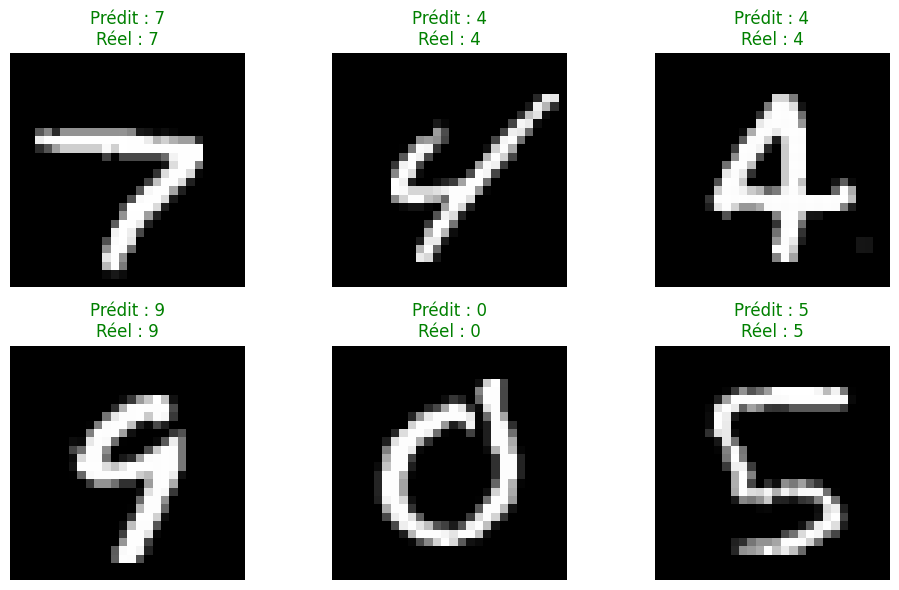

In [ ]:
import matplotlib.pyplot as plt
import random

# Récupérer un batch d'images de test
images, labels = next(iter(test_dataloader))
with torch.no_grad():
    outputs = modele(images)
    _, predictions = torch.max(outputs, 1)

# Afficher 6 images aléatoires du batch avec leurs prédictions
fig = plt.figure(figsize=(10, 6))
indices = random.sample(range(len(images)), 6)

for idx, i in enumerate(indices):
    plt.subplot(2, 3, idx + 1)
    # Remodeler l'image de [1, 28, 28] à [28, 28] pour l'affichage
    plt.imshow(images[i].squeeze(), cmap='gray')
    color = "green" if predictions[i] == labels[i] else "red"
    plt.title(f"Prédit : {predictions[i].item()}\nRéel : {labels[i].item()}", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

### 1. La Matrice de Confusion

#### Intérêt
L'exactitude globale (Accuracy) ne donne pas l'image complète. Par exemple, si un modèle a 93% de précision, on ne sait pas s'il répartit ses erreurs de manière homogène ou s'il confond systématiquement deux chiffres spécifiques (comme le 4 et le 9, ou le 3 et le 8). La **matrice de confusion** permet de visualiser précisément ces erreurs d'aiguillage.

#### Définition Mathématique
Pour un problème de classification à $C$ classes, la matrice de confusion $M 	imes M$ (notée $C$) est définie telle que chaque élément $C_{i, j}$ correspond au nombre d'observations appartenant réellement à la classe $i$ (en ligne) mais que le modèle a prédites comme appartenant à la classe $j$ (en colonne).

- Les éléments sur la **diagonale principale** ($C_{i, i}$) représentent les prédictions correctes.
- Les éléments hors-diagonale ($C_{i, j}$ avec $i \neq j$) représentent les erreurs de prédiction.

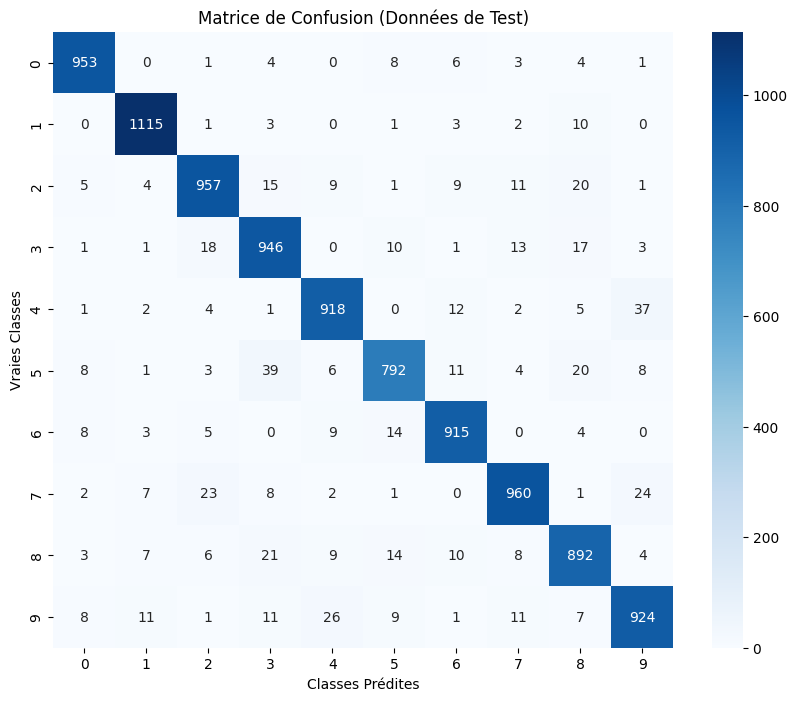

In [ ]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

all_preds = []
all_labels = []

# Extraction de toutes les prédictions sur le jeu de test
with torch.no_grad():
    for batch in test_dataloader:
        images, labels = batch
        outputs = modele(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

# Calcul de la matrice de confusion
cm = confusion_matrix(all_labels, all_preds)

# Affichage sous forme de carte de chaleur (heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10))
plt.title("Matrice de Confusion (Données de Test)")
plt.ylabel("Vraies Classes")
plt.xlabel("Classes Prédites")
plt.show()

### 2. Analyse des classes où le modèle se trompe le plus souvent

Nous allons extraire de notre matrice de confusion les paires de classes les plus fréquemment confondues (en excluant la diagonale principale où les prédictions sont correctes).

In [ ]:
# On met à 0 la diagonale pour ne garder que les erreurs
np.fill_diagonal(cm, 0)

# Trouver les indices des pires erreurs (triés par ordre décroissant)
flat_indices = np.argsort(cm.flat)[::-1]

print("--- Les 5 erreurs de confusion les plus fréquentes ---")
for idx in flat_indices[:5]:
    vraie_classe, pred_classe = np.unravel_index(idx, cm.shape)
    nb_erreurs = cm[vraie_classe, pred_classe]
    if nb_erreurs > 0:
        print(f"Le modèle a confondu un {vraie_classe} avec un {pred_classe} : {nb_erreurs} fois")

--- Les 5 erreurs de confusion les plus fréquentes ---
Le modèle a confondu un 5 avec un 3 : 39 fois
Le modèle a confondu un 4 avec un 9 : 37 fois
Le modèle a confondu un 9 avec un 4 : 26 fois
Le modèle a confondu un 7 avec un 9 : 24 fois
Le modèle a confondu un 7 avec un 2 : 23 fois


### 3. Sauvegarde du modèle

En PyTorch, la méthode recommandée est de sauvegarder uniquement les paramètres appris (les poids et biais), ce qu'on appelle le `state_dict`. C'est beaucoup plus léger et flexible.

In [ ]:
# Sauvegarde des poids du modèle dans un fichier
torch.save(modele.state_dict(), "modele_mnist.pth")
print("Modèle sauvegardé avec succès sous 'modele_mnist.pth' !")

# Exemple de chargement ultérieur des poids :
# 1. On recrée une instance vierge de notre architecture
modele_charge = ReseauBasique()
# 2. On charge les poids sauvegardés
modele_charge.load_state_dict(torch.load("modele_mnist.pth"))
# 3. On bascule le modèle en mode évaluation
modele_charge.eval()

Modèle sauvegardé avec succès sous 'modele_mnist.pth' !


ReseauBasique(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=10, bias=True)
  )
)

### Nouvelle Architecture : Réseau de Neurones Convolutif (CNN)

Voici une architecture CNN performante composée de :
- Deux couches de **Convolution** (`nn.Conv2d`) pour extraire les caractéristiques visuelles.
- Deux couches de **Max Pooling** (`nn.MaxPool2d`) pour réduire la taille spatiale et gagner en robustesse aux variations.
- Des couches entièrement connectées (**Dense Layers**) à la fin pour la classification.

### Théorie et Formalisation Mathématique des CNN

Contrairement à une couche linéaire classique qui effectue un produit matriciel global, une couche convolutive applique un filtre local glissant.

#### 1. L'Opération de Convolution 2D

Soit :
- $X \in \mathbb{R}^{H \times W}$ une image d'entrée (ou une carte de caractéristiques) à un seul canal.
- $K \in \mathbb{R}^{k_h \times k_w}$ un filtre (ou noyau de convolution), généralement de petite taille (ex: $3 \times 3$ ou $5 \times 5$).
- $b \in \mathbb{R}$ un biais scalaire.

La valeur de la carte de caractéristiques de sortie $S$ à la position $(i, j)$ est calculée en faisant la somme du produit terme à terme (produit de Hadamard) entre le filtre et la zone correspondante de l'image, puis en ajoutant le biais :

$$S(i, j) = (X * K)(i, j) + b = \sum_{m=0}^{k_h - 1} \sum_{n=0}^{k_w - 1} X(i + m, j + n) \cdot K(m, n) + b$$

Chaque filtre apprend à détecter un motif précis : des lignes verticales, des contours obliques, ou des textures.

#### 2. Dimensions de Sortie (Formule du Shape)

Si l'image d'entrée a une hauteur $H$ et une largeur $W$, et que l'on applique :
- Un filtre de taille $K_h \times K_w$
- Un rembourrage (Padding) $P$
- Un pas de glissement (Stride) $S$

La dimension de sortie $H_{out} \times W_{out}$ est donnée par la formule :

$$H_{out} = \left\lfloor \frac{H - K_h + 2P}{S} \right\rfloor + 1$$
$$W_{out} = \left\lfloor \frac{W - K_w + 2P}{S} \right\rfloor + 1$$

#### 3. Le Max-Pooling (Sous-échantillonnage)

La couche de Pooling permet de réduire la dimension spatiale des cartes de caractéristiques tout en conservant les informations les plus importantes. Le **Max-Pooling** avec une fenêtre de taille $2 \times 2$ et un pas de $2$ découpe l'image en blocs disjoints de $2 \times 2$ pixels et ne garde que la valeur maximale de chaque bloc :

$$P(i, j) = \max_{m, n \in \{0, 1\}} X(2i + m, 2j + n)$$

Cela permet de :
- Réduire de moitié la hauteur et la largeur (donc diviser par 4 le nombre de pixels à traiter).
- Rendre le réseau robuste aux petites translations du motif détecté.

### 4. Équation matricielle de la Convolution

Voici la formulation mathématique simplifiée de l'opération de convolution, d'abord localement puis généralisée à toute l'image.

#### A. Pour une seule zone locale de l'image (Un filtre)

Quand un filtre se pose sur une zone précise de l'image, le calcul de la somme de Hadamard (somme des produits cellule par cellule) se ramène à un produit scalaire entre deux vecteurs :
* $X_{zone}$ : les pixels de la petite zone de l'image mis à plat (vecteur ligne).
* $W_{filtre}$ : les poids du filtre mis à plat (vecteur colonne).
* $b$ : le biais (un nombre unique associé au filtre).

La valeur de sortie unique $S$ pour cette zone est :

$$S = X_{zone} \cdot W_{filtre} + b$$

#### B. Généralisation à toute l'image (Plusieurs filtres et zones)

Pour calculer l'ensemble des sorties d'un coup de manière extrêmement efficace, on regroupe toutes les zones de l'image et tous les filtres dans des matrices :
* **La matrice des activations d'entrée ($X$)** : chaque ligne contient les pixels d'une zone locale de l'image mise à plat.
* **La matrice des poids ($W$)** : chaque colonne contient les poids mis à plat d'un filtre spécifique.
* **Le vecteur de biais ($B$)** : contient le biais associé à chaque filtre.

L'équation globale de la convolution pour toute l'image devient alors une simple et unique multiplication matricielle :

$$\text{Cartes de Sortie} = X \times W + B$$

### Schéma du calcul matriciel de la Convolution (Im2Col)

Voici comment PyTorch convertit l'opération de convolution glissante en une unique multiplication de matrices géantes pour maximiser les performances du processeur ou du GPU :

$$\underbrace{\begin{pmatrix} \leftarrow & \vec{x}_{zone 1} & \rightarrow \\ \leftarrow & \vec{x}_{zone 2} & \rightarrow \\ & \vdots & \\ \leftarrow & \vec{x}_{zone M} & \rightarrow \end{pmatrix}}_{X_{reformat\acute{e}e} \text{ (Zones de l'image)}} \times \underbrace{\begin{pmatrix} \uparrow & \uparrow & \\ \vec{w}_{filtre 1} & \vec{w}_{filtre 2} & \dots \\ \downarrow & \downarrow & \end{pmatrix}}_{W \text{ (Filtres)}} = \underbrace{\begin{pmatrix} s_{1,1} & s_{1,2} & \dots \\ s_{2,1} & s_{2,2} & \dots \\ \vdots & \vdots & \\ s_{M,1} & s_{M,2} & \dots \end{pmatrix}}_{\text{Cartes de caract	ristiques de sortie}}$$

In [ ]:
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Première couche de convolution : prend 1 canal (gris), applique 16 filtres de taille 3x3
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) # Divise la taille de l'image par 2 (28x28 -> 14x14)

        # Deuxième couche de convolution : prend 16 canaux, applique 32 filtres
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) # Divise à nouveau par 2 (14x14 -> 7x7)

        # Couches fully-connected pour la décision finale
        # L'image finale est de dimension 32 canaux x 7 x 7 pixels
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # x a une taille de [batch_size, 1, 28, 28]
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

# Instanciation de notre nouveau modèle convolutif
modele_cnn = ConvNet()
print(modele_cnn)

ConvNet(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
class ConvNetDynamique(nn.Module):
    def __init__(self, input_shape=(1, 28, 28)):
        super().__init__()

        # On définit notre bloc de convolution sous forme de Sequential pour l'appeler facilement
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=input_shape[0], out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # --- ASTUCE : Calcul automatique de la taille de sortie ---
        # On crée un tenseur factice (un lot de taille 1)
        mock_input = torch.zeros(1, *input_shape)
        # On le fait passer dans les couches de convolution
        mock_output = self.features(mock_input)
        # On récupère le nombre total d'éléments une fois aplati
        num_features_flat = mock_output.numel()

        print(f"[Calcul Dynamique] Taille de sortie des convolutions aplatie : {num_features_flat}")

        # Maintenant, on peut configurer nn.Linear sans aucun calcul manuel !
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(num_features_flat, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

# Test du modèle dynamique
modele_dynamique = ConvNetDynamique(input_shape=(1, 28, 28))
print(modele_dynamique)

### Entraînement du modèle convolutif (`ConvNet`)

In [ ]:
import torch.optim as optim

# Configuration de l'appareil (GPU si disponible, sinon CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation de l'appareil : {device}")

# Transfert du modèle sur l'appareil
modele_cnn = ConvNet().to(device)

# Définition de l'optimiseur (Adam est généralement plus rapide et performant pour les CNN)
optimizer_cnn = optim.Adam(modele_cnn.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

# Boucle d'entraînement sur 5 époques
epoches = 5
for epoque in range(epoches):
    modele_cnn.train()
    perte_totale = 0
    for images, labels in train_dataloader:
        # Envoyer les données sur le GPU/CPU
        images, labels = images.to(device), labels.to(device)

        # Passage avant
        outputs = modele_cnn(images)
        loss = loss_fn(outputs, labels)

        # Rétropropagation et optimisation
        optimizer_cnn.zero_grad()
        loss.backward()
        optimizer_cnn.step()

        perte_totale += loss.item()

    print(f"Époque {epoque+1}/{epoches} - Perte moyenne : {perte_totale/len(train_dataloader):.4f}")

Utilisation de l'appareil : cpu
Époque 1/5 - Perte moyenne : 0.2304
Époque 2/5 - Perte moyenne : 0.0626
Époque 3/5 - Perte moyenne : 0.0439
Époque 4/5 - Perte moyenne : 0.0330
Époque 5/5 - Perte moyenne : 0.0271


### Évaluation de la précision du CNN sur le jeu de test

In [ ]:
modele_cnn.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = modele_cnn(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy_cnn = 100 * correct / total
print(f"Précision (Accuracy) du CNN sur les {total} images de test : {accuracy_cnn:.2f}%")

Précision (Accuracy) du CNN sur les 10000 images de test : 98.82%
